# Forecasting Premier League results vs the betting market

**Question:** how well can a model built on public data forecast the result of a Premier League match
(home win, draw or away win) before kickoff, compared with bookmaker odds?

**Data:** football-data.co.uk season files, 2012/13 to 2025/26: results, match statistics and bookmaker odds.

**Season roles**
- 2012/13: warm-up. Used to build ratings and rolling features, never scored.
- 2013/14 to 2019/20: training history.
- 2020/21 to 2024/25: test seasons, each predicted using only earlier seasons (walk-forward). Used to choose the model.
- 2025/26: final holdout, scored once with the chosen model (section 8).

**Metric:** log loss, the average of `-ln(p)` where `p` is the probability given to the result that happened.
Lower is better. Accuracy is not used: it ignores the probabilities and rewards always picking the most common result.

In [1]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

import numpy as np
import sklearn
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Seasons and their roles
SEASONS = ["2012-2013", "2013-2014", "2014-2015", "2015-2016", "2016-2017", "2017-2018", "2018-2019",
           "2019-2020", "2020-2021", "2021-2022", "2022-2023", "2023-2024", "2024-2025"]
WARMUP_SEASONS = SEASONS[:1]    # 2012/13
TRAIN_SEASONS = SEASONS[1:8]    # 2013/14 to 2019/20
TEST_SEASONS = SEASONS[8:]      # 2020/21 to 2024/25

# A season: 20 teams, each plays the 19 others at home and away
MATCHES_PER_SEASON = 380
GAMES_PER_TEAM = 38

# Columns kept from the raw files
ID_COLS = ["Season", "Date", "HomeTeam", "AwayTeam"]
RESULT_COLS = ["FTHG", "FTAG", "FTR"]        # full-time home goals, away goals, result (H/D/A)
STAT_COLS = ["HS", "AS", "HST", "AST"]       # shots and shots on target, home and away
PRE_CLOSE_ODDS_COLS = ["PSH", "PSD", "PSA"]  # Pinnacle odds collected a few days before the match (home, draw, away)
CLOSE_ODDS_COLS = ["PSCH", "PSCD", "PSCA"]   # Pinnacle closing odds: last price before kickoff
COLS = ID_COLS + RESULT_COLS + STAT_COLS + PRE_CLOSE_ODDS_COLS + CLOSE_ODDS_COLS
KEY_COLS = ["Date", "HomeTeam", "AwayTeam"]  # identifies one match

# The three outcomes in alphabetical order: the column order scikit-learn uses for probabilities
OUTCOMES = ["A", "D", "H"]

print("Versions | pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)


Versions | pandas 2.3.3 | numpy 1.26.4 | scikit-learn 1.7.2


## 1. Data inspection

Before merging, check that the 13 season files contain the same columns and clean data.
The 2025/26 file is kept aside as the final holdout and loaded only in section 8 (its Pinnacle odds stop in January 2026).

In [2]:
seasons_data = {}     # season -> table of that season

for season in SEASONS:
    df = pd.read_csv(season + ".csv")

    # Completely empty rows are export artifacts, not matches
    blank_rows = df.isna().all(axis=1)
    if blank_rows.sum() > 0:
        print("Dropped", blank_rows.sum(), "blank row(s) in", season)
    df = df[~blank_rows].copy()

    df["Season"] = season
    seasons_data[season] = df

# Every file must contain the columns we need
for season in SEASONS:
    for col in COLS:
        assert col in seasons_data[season].columns, season + " is missing column " + col
print("All files contain the needed columns")

Dropped 1 blank row(s) in 2014-2015
All files contain the needed columns


### Checks per season

A season is clean if it has 380 matches, no missing values, no duplicate matches, every team plays 19 home
and 19 away games, the result column agrees with the goals, and the dates fall in the right years.

In [3]:
rows = []
for season in SEASONS:
    df = seasons_data[season]
    dates = pd.to_datetime(df["Date"], dayfirst=True, format="mixed")    # 2012/13 uses 2-digit years

    # Rebuild the result from the goals, to compare with the FTR column
    result_from_goals = pd.Series("D", index=df.index)
    result_from_goals[df["FTHG"] > df["FTAG"]] = "H"
    result_from_goals[df["FTHG"] < df["FTAG"]] = "A"

    rows.append({
        "season": season,
        "rows": len(df),
        "missing_values": df[COLS].isna().sum().sum(),
        "duplicate_matches": df.duplicated(subset=KEY_COLS).sum(),
        "teams": df["HomeTeam"].nunique(),
        "19_home_games_each": (df["HomeTeam"].value_counts() == 19).all(),
        "19_away_games_each": (df["AwayTeam"].value_counts() == 19).all(),
        "wrong_results": (result_from_goals != df["FTR"]).sum(),
        "first_date": dates.min(),
        "last_date": dates.max(),
    })

checks = pd.DataFrame(rows)
display(checks)

assert (checks["rows"] == MATCHES_PER_SEASON).all()
assert (checks["missing_values"] == 0).all()
assert (checks["duplicate_matches"] == 0).all()
assert checks["19_home_games_each"].all() and checks["19_away_games_each"].all()
assert (checks["wrong_results"] == 0).all()
assert (checks["first_date"].dt.year == checks["season"].str[:4].astype(int)).all()   # 2012-2013 starts in 2012
assert (checks["last_date"].dt.year == checks["season"].str[5:].astype(int)).all()    # and ends in 2013
print("All season checks passed")

,season,rows,missing_values,duplicate_matches,teams,19_home_games_each,19_away_games_each,wrong_results,first_date,last_date
0,2012-2013,380,0,0,20,True,True,0,2012-08-18,2013-05-19
1,2013-2014,380,0,0,20,True,True,0,2013-08-17,2014-05-11
2,2014-2015,380,0,0,20,True,True,0,2014-08-16,2015-05-24
3,2015-2016,380,0,0,20,True,True,0,2015-08-08,2016-05-17
4,2016-2017,380,0,0,20,True,True,0,2016-08-13,2017-05-21
5,2017-2018,380,0,0,20,True,True,0,2017-08-11,2018-05-13
6,2018-2019,380,0,0,20,True,True,0,2018-08-10,2019-05-12
7,2019-2020,380,0,0,20,True,True,0,2019-08-09,2020-07-26
8,2020-2021,380,0,0,20,True,True,0,2020-09-12,2021-05-23
9,2021-2022,380,0,0,20,True,True,0,2021-08-13,2022-05-22


All season checks passed


**Conclusion:** all 13 seasons pass every check. The only fix needed was one blank row at the end of the
2014/15 file, removed when loading. The 2019/20 season ends in July 2020 and 2020/21 starts in September 2020
because of COVID.

### Team names across seasons

Every team plays at home in each of its seasons, so counting the seasons per home-team name shows whether one
club appears under two spellings (two names with few seasons each).

In [4]:
home_teams = pd.concat(seasons_data.values())[["Season", "HomeTeam"]]
seasons_per_team = home_teams.groupby("HomeTeam")["Season"].nunique().sort_values(kind="stable")   # stable: ties stay alphabetical
print("Distinct teams:", len(seasons_per_team))
display(seasons_per_team)

Distinct teams: 37


HomeTeam
Ipswich              1
Luton                1
Middlesbrough        1
Reading              1
Wigan                1
Cardiff              2
Huddersfield         2
QPR                  2
Hull                 3
Leeds                3
Nott'm Forest        3
Sheffield United     3
Brentford            4
Norwich              5
Sunderland           5
Stoke                6
Swansea              6
Watford              6
Fulham               7
West Brom            7
Wolves               7
Bournemouth          8
Brighton             8
Burnley              8
Aston Villa         10
Leicester           10
Crystal Palace      12
Newcastle           12
Southampton         12
Arsenal             13
Chelsea             13
Everton             13
Liverpool           13
Man City            13
Man United          13
Tottenham           13
West Ham            13
Name: Season, dtype: int64

**Conclusion:** 37 distinct clubs. Names are consistent across all seasons, and the clubs with one or two
seasons are genuine short stays, not spelling variants. No name standardization is needed.

## 2. Cleaning and merging

Keep only the needed columns, stack the 13 seasons into one table, parse the dates and sort the matches.
The sort is by `Date`, then `HomeTeam`, so the order is always the same: ratings and rolling features are
built match by match in this order.

In [5]:
matches = pd.concat(seasons_data.values(), ignore_index=True)[COLS]
matches["Date"] = pd.to_datetime(matches["Date"], dayfirst=True, format="mixed")
matches = matches.sort_values(["Date", "HomeTeam"]).reset_index(drop=True)

assert len(matches) == len(SEASONS) * MATCHES_PER_SEASON
assert matches[COLS].isna().sum().sum() == 0
assert matches.duplicated(subset=KEY_COLS).sum() == 0
assert matches["Date"].is_monotonic_increasing
assert (matches["Season"].value_counts() == MATCHES_PER_SEASON).all()
print("Merged table checks passed")

# Goals and shots were read as decimals because of the blank row; they are whole numbers
int_cols = ["FTHG", "FTAG"] + STAT_COLS
matches[int_cols] = matches[int_cols].astype("int64")

print("Shape:", matches.shape)
print("Dates:", matches["Date"].min().date(), "to", matches["Date"].max().date())
display(matches.head())

Merged table checks passed
Shape: (4940, 17)
Dates: 2012-08-18 to 2025-05-25


,Season,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HS,AS,HST,AST,PSH,PSD,PSA,PSCH,PSCD,PSCA
0,2012-2013,2012-08-18,Arsenal,Sunderland,0,0,D,14,3,4,2,1.44,4.76,8.78,1.44,4.72,8.71
1,2012-2013,2012-08-18,Fulham,Norwich,5,0,H,11,4,9,2,1.82,3.81,4.80,1.84,3.75,4.75
2,2012-2013,2012-08-18,Newcastle,Tottenham,2,1,H,6,12,4,6,2.65,3.47,2.82,2.83,3.35,2.72
3,2012-2013,2012-08-18,QPR,Swansea,0,5,A,20,12,11,8,2.05,3.53,4.01,2.00,3.53,4.15
4,2012-2013,2012-08-18,Reading,Stoke,1,1,D,9,6,3,3,2.40,3.37,3.26,2.47,3.30,3.22


**Conclusion:** `matches` has 4,940 rows (13 seasons × 380) and 17 columns, from 2012-08-18 to 2025-05-25,
with no missing values or duplicates. Corners, fouls and cards are not kept: the project does not use them.

## 3. Baselines

Simple forecasts that any model has to beat, scored on the test seasons:

1. **Always home win:** scored by accuracy only. It gives probability 0 to draws and away wins, so its log loss is infinite.
2. **Uniform:** 1/3 for each outcome.
3. **Historical frequencies:** the outcome shares of the training seasons, the same forecast for every match.
4. **Market:** Pinnacle odds turned into probabilities: pre-closing (collected a few days before the match, on Friday or
   Tuesday afternoon) and closing (last price before kickoff).

### Outcome shares

The frequency baseline must use the training seasons only: using the test seasons' shares would mean using results not yet played.

In [6]:
train_matches = matches[matches["Season"].isin(TRAIN_SEASONS)]
test_matches = matches[matches["Season"].isin(TEST_SEASONS)]

shares = pd.DataFrame({
    "train": train_matches["FTR"].value_counts(normalize=True),
    "test": test_matches["FTR"].value_counts(normalize=True),
})
display(shares.round(3))

,train,test
FTR,,
H,0.459,0.432
A,0.306,0.340
D,0.235,0.228


**Conclusion:** home wins fell from 45.9% in training to 43.2% in the test seasons, away wins rose from 30.6% to 34.0%,
and draws stayed about the same (23.5% and 22.8%). "Always home win" is right 43.2% of the time in the test seasons.

### From odds to probabilities

Decimal odds of 2.00 imply a probability of 1 / 2.00 = 0.50. The three implied probabilities of a match add up to
slightly more than 1: the extra part is the bookmaker's margin (overround). Dividing each by their sum removes it.

In [7]:
def market_probs(df, odds_cols):
    """Odds (home, draw, away) -> probabilities without the margin, columns A, D, H."""
    home_col, draw_col, away_col = odds_cols
    implied_home = 1 / df[home_col]
    implied_draw = 1 / df[draw_col]
    implied_away = 1 / df[away_col]
    total = implied_home + implied_draw + implied_away        # above 1 because of the margin
    return pd.DataFrame({"A": implied_away / total, "D": implied_draw / total, "H": implied_home / total})


# Check the odds: all above 1, and a margin (total of implied probabilities) slightly above 1
assert (matches[PRE_CLOSE_ODDS_COLS + CLOSE_ODDS_COLS] > 1).all().all()
margins = pd.DataFrame({
    "Season": matches["Season"],
    "pre_closing": 1 / matches["PSH"] + 1 / matches["PSD"] + 1 / matches["PSA"],
    "closing": 1 / matches["PSCH"] + 1 / matches["PSCD"] + 1 / matches["PSCA"],
})
assert (margins["pre_closing"] > 1).all() and (margins["closing"] > 1).all()
display(margins.groupby("Season").agg(["min", "max"]).round(3))

pre_closing        closing       
                  min    max     min    max
Season                                     
2012-2013       1.017  1.026   1.014  1.031
2013-2014       1.016  1.024   1.014  1.053
2014-2015       1.012  1.025   1.014  1.027
2015-2016       1.017  1.024   1.017  1.026
2016-2017       1.015  1.032   1.017  1.030
2017-2018       1.017  1.045   1.012  1.034
2018-2019       1.017  1.038   1.018  1.038
2019-2020       1.021  1.045   1.021  1.041
2020-2021       1.018  1.059   1.017  1.039
2021-2022       1.021  1.047   1.001  1.044
2022-2023       1.021  1.047   1.007  1.043
2023-2024       1.024  1.057   1.019  1.040
2024-2025       1.027  1.053   1.006  1.042

**Conclusion:** every odd is above 1 and every margin is above 1: from 1.012 to 1.059 for pre-closing odds and from 1.001
to 1.053 for closing odds, a normal bookmaker margin.

### Scoring the baselines

In [8]:
# Each forecast is a table: one row per test match, columns A, D, H
uniform_probs = pd.DataFrame({"A": 1 / 3, "D": 1 / 3, "H": 1 / 3}, index=test_matches.index)
frequency_probs = pd.DataFrame({"A": shares.loc["A", "train"],
                                "D": shares.loc["D", "train"],
                                "H": shares.loc["H", "train"]}, index=test_matches.index)
pre_closing_probs = market_probs(test_matches, PRE_CLOSE_ODDS_COLS)
closing_probs = market_probs(test_matches, CLOSE_ODDS_COLS)

results = test_matches["FTR"]
baselines = pd.Series({
    "Uniform": log_loss(results, uniform_probs, labels=OUTCOMES),
    "Frequency": log_loss(results, frequency_probs, labels=OUTCOMES),
    "Market, pre-closing": log_loss(results, pre_closing_probs, labels=OUTCOMES),
    "Market, closing": log_loss(results, closing_probs, labels=OUTCOMES),
}, name="log_loss")
display(baselines.round(4))

Uniform                1.0986
Frequency              1.0691
Market, pre-closing    0.9574
Market, closing        0.9524
Name: log_loss, dtype: float64

**Conclusion:** the frequencies improve on the uniform guess by only 0.030 (1.0986 to 1.0691): overall shares say little
about a single match. The market is much better: closing odds score 0.9524, 0.117 below the frequencies. Pre-closing odds
are close behind (0.9574). The market is the benchmark to approach; the realistic goal for a model built on public
data is to close part of the gap between 1.0691 and 0.9524.

## 4. Features

Every feature uses only information available before kickoff. Two kinds:
- **Elo ratings**, computed match by match in date order.
- **Rolling team statistics** (form, goal difference, shots on target, promoted flag), computed from a team-level table.

All features are built here; section 5 tests them one group at a time.

### 4.1 Elo ratings

Every team starts at 1500. After each match, the home team gains `K × (actual score − expected score)` and the away
team loses the same amount (actual score: 1 win, 0.5 draw, 0 loss). A surprising result moves the ratings more than
an expected one. Home advantage is added to the home rating when computing the expectation.

For each match, the ratings are stored **before** the update, so a match's feature never contains its own result.
Ratings carry over between seasons. A club starts at 1500 the first time it appears in the data; a club that comes back
after relegation keeps the rating it had when it left, sometimes years earlier.

In [9]:
INITIAL_RATING = 1500
K_FACTOR = 20     # how fast ratings move (common starting value, not tuned)
HOME_ADV = 100    # rating points added to the home team in the expectation
SCORE_FOR_HOME = {"H": 1, "D": 0.5, "A": 0}


def expected_home_score(r_home, r_away):
    # Between 0 and 1; equal ratings and no home advantage would give 0.5
    return 1 / (1 + 10 ** ((r_away - (r_home + HOME_ADV)) / 400))


# Every team starts at 1500
ratings = {}
for team in matches["HomeTeam"].unique():
    ratings[team] = INITIAL_RATING

elo_home = []    # home team's rating before each match
elo_away = []    # away team's rating before each match

for i, match in matches.iterrows():          # matches are in date order
    home = match["HomeTeam"]
    away = match["AwayTeam"]

    # Store the ratings BEFORE the update: a match's feature never contains its own result
    elo_home.append(ratings[home])
    elo_away.append(ratings[away])

    # Update the ratings with the result
    expected = expected_home_score(ratings[home], ratings[away])
    actual = SCORE_FOR_HOME[match["FTR"]]
    change = K_FACTOR * (actual - expected)
    ratings[home] = ratings[home] + change
    ratings[away] = ratings[away] - change

matches["elo_home"] = elo_home
matches["elo_away"] = elo_away
matches["elo_diff"] = matches["elo_home"] - matches["elo_away"]

assert len(ratings) == 37
assert matches.loc[0, "elo_home"] == INITIAL_RATING and matches.loc[0, "elo_away"] == INITIAL_RATING
assert np.isclose(sum(ratings.values()), len(ratings) * INITIAL_RATING)
print("Elo checks passed")

final_ratings = pd.Series(ratings).sort_values(ascending=False).round(1)
display(final_ratings.head(5))
display(final_ratings.tail(5))

Elo checks passed


Liverpool      1780.0
Man City       1777.8
Arsenal        1763.6
Chelsea        1674.8
Aston Villa    1667.2
dtype: float64

QPR                 1368.2
Huddersfield        1347.5
Sheffield United    1346.5
Norwich             1330.5
Southampton         1328.7
dtype: float64

**Conclusion:** ratings were computed for all 4,940 matches; the checks pass. After 2024/25, Liverpool, Man City and
Arsenal are at the top. The bottom is mostly clubs that left the league, whose ratings stopped changing, so this table
is a sanity check, not a ranking of current strength.

### 4.2 Does Elo carry signal?

A quick check, not a model: split the matches (warm-up excluded, its ratings have not settled) into five groups of
equal size by `elo_diff` and compare the outcome shares in each group.

In [10]:
signal = matches[~matches["Season"].isin(WARMUP_SEASONS)].copy()
signal["elo_group"] = pd.qcut(signal["elo_diff"], 5)
shares_by_group = signal.groupby("elo_group", observed=True)["FTR"].value_counts(normalize=True)
display(shares_by_group.unstack().round(3))

FTR,A,D,H
elo_group,,,
"(-495.83, -131.355]",0.609,0.193,0.198
"(-131.355, -33.555]",0.394,0.268,0.339
"(-33.555, 34.205]",0.271,0.294,0.435
"(34.205, 134.489]",0.219,0.242,0.538
"(134.489, 499.405]",0.110,0.162,0.728


**Conclusion:** `elo_diff` carries a strong signal. As the home team's rating edge grows, home wins rise from about 20%
to 73% and away wins fall from about 61% to 11%. Draws are most common when the teams are close. With equal ratings,
home wins (44%) still beat away wins (27%): home advantage.

### 4.3 Team-level table

Form and rolling statistics belong to a team across all its matches, home and away. So each match becomes two rows,
one from each team's point of view, with goals and shots on target "for" and "against".

In [11]:
matches["match_id"] = matches.index      # links the two team rows back to their match

HOME_VIEW = {"HomeTeam": "team", "AwayTeam": "opponent", "FTHG": "goals_for", "FTAG": "goals_against",
             "HST": "sot_for", "AST": "sot_against"}
AWAY_VIEW = {"AwayTeam": "team", "HomeTeam": "opponent", "FTAG": "goals_for", "FTHG": "goals_against",
             "AST": "sot_for", "HST": "sot_against"}           # roles swapped for the away team
view_cols = ["match_id", "Season", "Date"] + list(HOME_VIEW)

home_rows = matches[view_cols].rename(columns=HOME_VIEW)
home_rows["venue"] = "H"
away_rows = matches[view_cols].rename(columns=AWAY_VIEW)
away_rows["venue"] = "A"

team_table = pd.concat([home_rows, away_rows]).sort_values(["Date", "match_id"]).reset_index(drop=True)
team_table["points"] = 0
team_table.loc[team_table["goals_for"] > team_table["goals_against"], "points"] = 3    # win
team_table.loc[team_table["goals_for"] == team_table["goals_against"], "points"] = 1   # draw
team_table["gd"] = team_table["goals_for"] - team_table["goals_against"]      # goal difference
team_table["sotd"] = team_table["sot_for"] - team_table["sot_against"]        # shots-on-target difference

assert len(team_table) == 2 * len(matches)
assert (team_table.groupby(["Season", "team"]).size() == GAMES_PER_TEAM).all()
print("Team table checks passed | mean points per match:", round(team_table["points"].mean(), 3))
display(team_table.head(4))

Team table checks passed | mean points per match: 1.382


,match_id,Season,Date,team,opponent,goals_for,goals_against,sot_for,sot_against,venue,points,gd,sotd
0,0,2012-2013,2012-08-18,Arsenal,Sunderland,0,0,4,2,H,1,0,2
1,0,2012-2013,2012-08-18,Sunderland,Arsenal,0,0,2,4,A,1,0,-2
2,1,2012-2013,2012-08-18,Fulham,Norwich,5,0,9,2,H,3,5,7
3,1,2012-2013,2012-08-18,Norwich,Fulham,0,5,2,9,A,0,-5,-7


**Conclusion:** 9,880 rows (two per match), and every team has 38 matches in each season it played. The first match,
Arsenal 0–0 Sunderland, shows the swap: Arsenal's row has 4 shots on target for and 2 against, Sunderland's the reverse.

### 4.4 Rolling features

For each team, the average of its **previous** matches; `shift(1)` leaves out the current match. Two windows:
- **last 5 matches**, carried over between seasons: form (`form5`, points), goal difference (`gd5`), shots-on-target difference (`sotd5`);
- **season to date**, restarted each season: `gd_season`, `sotd_season`.

A team's first match has no previous match, so its value is missing. Missing values are filled later, inside the model,
with the mean of the training data.

In [12]:
FORM_WINDOW = 5

for col in ["form5", "gd5", "sotd5", "gd_season", "sotd_season"]:
    team_table[col] = np.nan

# Last 5 matches
for team in team_table["team"].unique():
    rows = team_table["team"] == team
    for source, target in [("points", "form5"), ("gd", "gd5"), ("sotd", "sotd5")]:
        previous = team_table.loc[rows, source].shift(1)     # shift(1): previous matches only
        team_table.loc[rows, target] = previous.rolling(FORM_WINDOW, min_periods=1).mean()

# Season to date: one team and one season at a time (restarts each season)
for team in team_table["team"].unique():
    for season in SEASONS:
        rows = (team_table["team"] == team) & (team_table["Season"] == season)
        if rows.sum() == 0:
            continue                                # the team was not in the league that season
        for source, target in [("gd", "gd_season"), ("sotd", "sotd_season")]:
            previous = team_table.loc[rows, source].shift(1)
            team_table.loc[rows, target] = previous.expanding().mean()

# Missing values: one per club for the last-5 features, one per club-season for the season-to-date ones
n_clubs = team_table["team"].nunique()
n_club_seasons = team_table.groupby(["team", "Season"]).ngroups
for col in ["form5", "gd5", "sotd5"]:
    assert team_table[col].isna().sum() == n_clubs
for col in ["gd_season", "sotd_season"]:
    assert team_table[col].isna().sum() == n_club_seasons
print("Rolling feature checks passed")

# Check
display(team_table.loc[team_table["team"] == "Arsenal", ["Date", "points", "form5", "gd", "gd5"]].head(6))

Rolling feature checks passed


,Date,points,form5,gd,gd5
0,2012-08-18,1,NaN,0,NaN
39,2012-08-26,1,1.000000,0,0.000000
53,2012-09-02,3,1.000000,2,0.000000
58,2012-09-15,3,1.666667,5,0.666667
93,2012-09-23,1,2.000000,0,1.750000
98,2012-09-29,0,1.800000,-1,1.400000


**Conclusion:** missing values appear only where expected (37 for the last-5 features, 260 for the season-to-date
ones). In Arsenal's rows, each value is the average of the matches above it, so the current match is never included.

### 4.5 Promoted-team flag

A club is promoted if it was not in the league the previous season, which is known before the season starts.
Elo gives a promoted club either 1500 (the average, first appearance) or the rating it had when it was relegated,
often years earlier. Neither reflects its current level, and promoted clubs are usually among the weakest.
`promoted_fade` = flag × (1 − matches already played this season / 38): full weight in the first match,
close to zero at the end, as Elo learns the club's level. The flag cannot be computed for 2012/13 (no previous season
in the data), which is the warm-up.

In [13]:
team_table["promoted"] = np.nan                 # stays missing in 2012/13: no previous season in the data

for i in range(1, len(SEASONS)):
    season = SEASONS[i]
    previous_season = SEASONS[i - 1]
    previous_clubs = team_table.loc[team_table["Season"] == previous_season, "team"].unique()
    rows = team_table["Season"] == season
    not_in_previous = ~team_table.loc[rows, "team"].isin(previous_clubs)
    team_table.loc[rows, "promoted"] = not_in_previous.astype(int)

games_played = team_table.groupby(["team", "Season"]).cumcount()      # matches already played this season
team_table["promoted_fade"] = team_table["promoted"] * (1 - games_played / GAMES_PER_TEAM)

promoted_clubs = team_table[team_table["promoted"] == 1].groupby("Season")["team"].unique()
assert len(promoted_clubs) == len(SEASONS) - 1 and (promoted_clubs.map(len) == 3).all()
print("Promoted-flag checks passed")
display(promoted_clubs)

Promoted-flag checks passed


Season
2013-2014             [Cardiff, Hull, Crystal Palace]
2014-2015                   [Leicester, QPR, Burnley]
2015-2016             [Bournemouth, Watford, Norwich]
2016-2017              [Burnley, Hull, Middlesbrough]
2017-2018         [Brighton, Huddersfield, Newcastle]
2018-2019                   [Cardiff, Fulham, Wolves]
2019-2020    [Norwich, Sheffield United, Aston Villa]
2020-2021                  [Fulham, Leeds, West Brom]
2021-2022               [Brentford, Norwich, Watford]
2022-2023        [Bournemouth, Fulham, Nott'm Forest]
2023-2024          [Burnley, Luton, Sheffield United]
2024-2025           [Ipswich, Southampton, Leicester]
Name: team, dtype: object

**Conclusion:** exactly 3 promoted clubs in every season from 2013/14, matching the real promotions. This also confirms
that team names are consistent: a misspelled club would look promoted.

### Considered but not tested: rest days

Rest between matches plausibly matters, but the data contains only Premier League matches. European and cup fixtures,
which add midweek games mainly for the top clubs, are missing, so rest days computed from league matches would be a
misleading proxy. Left as future work.

### 4.6 Join the team features to the match table

Each match gets every feature twice, for the home team (`_home`) and the away team (`_away`), plus the difference
home minus away (`_diff`).

In [14]:
TEAM_FEATURES = ["form5", "gd5", "sotd5", "gd_season", "sotd_season", "promoted", "promoted_fade"]

# One row per match for each side, indexed by match_id
home_side = team_table[team_table["venue"] == "H"].set_index("match_id")
away_side = team_table[team_table["venue"] == "A"].set_index("match_id")

for feature in TEAM_FEATURES:
    matches[feature + "_home"] = home_side[feature]
    matches[feature + "_away"] = away_side[feature]
    matches[feature + "_diff"] = matches[feature + "_home"] - matches[feature + "_away"]

assert (matches["match_id"] == matches.index).all()
print("Join done | columns:", matches.shape[1])

# How much the new features overlap with Elo (features only, no results used)
diff_cols = ["elo_diff", "form5_diff", "gd5_diff", "sotd5_diff", "gd_season_diff", "sotd_season_diff"]
display(matches[diff_cols].corr().round(2))

Join done | columns: 42


,elo_diff,form5_diff,gd5_diff,sotd5_diff,gd_season_diff,sotd_season_diff
elo_diff,1.00,0.66,0.67,0.64,0.78,0.74
form5_diff,0.66,1.00,0.89,0.66,0.68,0.59
gd5_diff,0.67,0.89,1.00,0.73,0.75,0.64
sotd5_diff,0.64,0.66,0.73,1.00,0.64,0.81
gd_season_diff,0.78,0.68,0.75,0.64,1.00,0.80
sotd_season_diff,0.74,0.59,0.64,0.81,0.80,1.00


**Conclusion:** the join keeps 4,940 matches. All the rolling features overlap with `elo_diff` (correlation 0.64 to 0.78),
less so for the last-5 features than for the season-to-date ones. A feature only helps if it adds information Elo does not already have.

## 5. Models

**Walk-forward:** each test season is predicted by a model trained on all earlier seasons (warm-up excluded):
5 fits, 2,660 to 4,180 training matches, 380 test matches each. A check confirms that no training match is later than a test match.

**Model:** multinomial logistic regression (three outcomes at once). Inside a pipeline, missing feature values are filled
with the training mean, and features are put on the same scale before the regression.

**Decision rule, set before any comparison:** a challenger replaces the reference model only if its log loss is lower
in at least 4 of the 5 test seasons **and** its mean gain is positive.

**Uncertainty:** every comparison also reports a 95% bootstrap interval of the mean gain: the 1,900 test matches are
resampled with replacement 2,000 times. The interval was added after the model was chosen, so it changes
no decision; it shows how much of each gain could be chance.

The frequency baseline here is re-computed for each fold from its own training seasons (mean 1.0687, slightly
different from 1.0691 in section 3).

In [15]:
MIN_WINS = 4
RANDOM_SEED = 42     # fixes every random step (bootstrap, gradient boosting)
N_BOOT = 2000        # bootstrap resamples
FIRST_TEST = SEASONS.index(TEST_SEASONS[0])     # position of the first test season (8)
LOGREG = make_pipeline(SimpleImputer(strategy="mean"), StandardScaler(), LogisticRegression())


def walk_forward(features, model):
    """Fit one model per test season on all earlier seasons; return the probabilities for every test match."""
    all_probs = []
    for i in range(FIRST_TEST, len(SEASONS)):           # one fit per test season
        train_seasons = SEASONS[1:i]                    # all earlier seasons, warm-up (position 0) excluded
        train = matches[matches["Season"].isin(train_seasons)]
        test = matches[matches["Season"] == SEASONS[i]]
        assert train["Date"].max() < test["Date"].min(), "Training data reaches into the test period"

        model.fit(train[features], train["FTR"])       # fit starts from scratch each time
        assert list(model.classes_) == OUTCOMES          # probability columns are A, D, H
        probs = pd.DataFrame(model.predict_proba(test[features]), columns=OUTCOMES, index=test.index)
        all_probs.append(probs)
    return pd.concat(all_probs)


def score_by_season(probs):
    """Log loss of each test season."""
    season_scores = {}
    for season in TEST_SEASONS:
        rows = matches.loc[probs.index, "Season"] == season
        results = matches.loc[probs.index[rows], "FTR"]
        season_scores[season] = log_loss(results, probs[rows], labels=OUTCOMES)
    return pd.Series(season_scores)


def gap_closed(name):
    """Share of the distance from the frequency baseline to the market covered by a model (mean over seasons)."""
    return ((scores["Frequency"] - scores[name]) / (scores["Frequency"] - scores["Market"])).mean()



def match_costs(match_probs, results):
    """Log loss of each single match: -ln(probability given to the result that happened)."""
    p_true = pd.Series(0.0, index=results.index)
    for outcome in OUTCOMES:
        happened = results == outcome
        p_true[happened] = match_probs.loc[happened, outcome]
    return -np.log(p_true)


def bootstrap_ci(differences):
    """95% interval of the mean of per-match differences, resampling matches with replacement."""
    rng = np.random.default_rng(RANDOM_SEED)
    values = differences.values
    means = []
    for b in range(N_BOOT):
        pick = rng.integers(0, len(values), len(values))
        means.append(values[pick].mean())
    return np.percentile(means, 2.5), np.percentile(means, 97.5)


probs = {}     # probabilities for the test matches
scores = {}    # log loss of each test season

# Frequency baseline on the same folds
probs["Frequency"] = walk_forward(["elo_diff"], DummyClassifier(strategy="prior"))
scores["Frequency"] = score_by_season(probs["Frequency"])

# Market (closing odds) on the same test matches
probs["Market"] = market_probs(matches.loc[probs["Frequency"].index], CLOSE_ODDS_COLS)
scores["Market"] = score_by_season(probs["Market"])

### 5.1 Model A: Elo difference only

In [16]:
FEATURES_A = ["elo_diff"]
probs["A"] = walk_forward(FEATURES_A, LOGREG)
scores["A"] = score_by_season(probs["A"])

display(pd.DataFrame(scores)[["Frequency", "A", "Market"]].round(4))
print("Mean log loss | frequency:", round(scores["Frequency"].mean(), 4), "| A:", round(scores["A"].mean(), 4),
      "| market:", round(scores["Market"].mean(), 4), "| A gap closed:", round(gap_closed("A"), 3))

,Frequency,A,Market
2020-2021,1.0880,1.0463,0.9971
2021-2022,1.0697,0.9521,0.9367
2022-2023,1.0503,0.9810,0.9622
2023-2024,1.0539,0.9281,0.8995
2024-2025,1.0815,0.9899,0.9664


Mean log loss | frequency: 1.0687 | A: 0.9795 | market: 0.9524 | A gap closed: 0.748


**Conclusion:** Elo alone beats the frequency baseline in all 5 seasons and never beats the market. It closes about 75%
of the gap between them (mean log loss 0.9795). The weakest season is 2020/21 (about 46%), the COVID season with empty
stadiums. **Model A is the reference.**

### 5.2 Model B: Elo + form

Does recent form (`form5_home`, `form5_away`) add anything to Elo?

In [17]:
def compare(reference, challenger):
    """Apply the decision rule; return one row for the experiment log."""
    gain = scores[reference] - scores[challenger]
    wins = int((gain > 0).sum())
    passes = wins >= MIN_WINS and gain.mean() > 0

    # Per-match gain, for the bootstrap interval (seasons have 380 matches each, so its mean equals gain.mean())
    results = matches.loc[probs[reference].index, "FTR"]
    match_gain = match_costs(probs[reference], results) - match_costs(probs[challenger], results)
    ci_low, ci_high = bootstrap_ci(match_gain)

    display(pd.DataFrame({reference: scores[reference], challenger: scores[challenger], "gain": gain}).round(4))
    print(challenger, "vs", reference, "| better in", wins, "of 5 seasons | mean gain:", round(gain.mean(), 4),
          "| 95% interval:", round(ci_low, 4), "to", round(ci_high, 4), "| passes:", passes)
    return {"challenger": challenger, "reference": reference, "wins": wins, "mean_gain": round(gain.mean(), 4),
            "ci_low": round(ci_low, 4), "ci_high": round(ci_high, 4), "passes": passes}


experiment_log = []      # every comparison made on the test seasons

FEATURES_B = FEATURES_A + ["form5_home", "form5_away"]
probs["B"] = walk_forward(FEATURES_B, LOGREG)
scores["B"] = score_by_season(probs["B"])
experiment_log.append(compare("A", "B"))

,A,B,gain
2020-2021,1.0463,1.0472,-0.0008
2021-2022,0.9521,0.9528,-0.0007
2022-2023,0.9810,0.9811,-0.0002
2023-2024,0.9281,0.9291,-0.0011
2024-2025,0.9899,0.9912,-0.0013


B vs A | better in 0 of 5 seasons | mean gain: -0.0008 | 95% interval: -0.0022 to 0.0005 | passes: False


In [18]:
# Diagnostic only, no decision: overlap of form with Elo, and form on its own
print("corr(form5_diff, elo_diff):", round(matches["form5_diff"].corr(matches["elo_diff"]), 2))
form_only = score_by_season(walk_forward(["form5_home", "form5_away"], LOGREG))
print("Form only, mean log loss:", round(form_only.mean(), 4))

corr(form5_diff, elo_diff): 0.66
Form only, mean log loss: 1.0303


**Conclusion:** B is worse than A in all 5 seasons (mean gain −0.0008): form is dropped and **A stays the reference**.
Elo is updated after every match and adjusts for the opponent's strength, so it already contains recent form
(correlation 0.66). Form alone does carry signal (1.030 against 1.069 for the frequency baseline), but nothing on top of Elo.

### 5.3 Model C: Elo + goal and shot differences

Elo only sees results. Goal difference adds the margin of victory; shots on target measure performance with less luck than goals.

| Variant | Features added to `elo_diff` |
|---|---|
| C1 | `gd5_diff`, `sotd5_diff` (last 5 matches) |
| C2 | `gd_season_diff`, `sotd_season_diff` (season to date) |
| C3 | all four |

**Rule for choosing among variants (set before running):** among the variants that pass against A, keep the one with the
fewest features (if C1 and C2 both pass, the larger mean gain). C3 is kept only if it also beats that variant.


In [19]:
FEATURES_C1 = FEATURES_A + ["gd5_diff", "sotd5_diff"]
FEATURES_C2 = FEATURES_A + ["gd_season_diff", "sotd_season_diff"]
FEATURES_C3 = FEATURES_A + ["gd5_diff", "sotd5_diff", "gd_season_diff", "sotd_season_diff"]

probs["C1"] = walk_forward(FEATURES_C1, LOGREG)
probs["C2"] = walk_forward(FEATURES_C2, LOGREG)
probs["C3"] = walk_forward(FEATURES_C3, LOGREG)
scores["C1"] = score_by_season(probs["C1"])
scores["C2"] = score_by_season(probs["C2"])
scores["C3"] = score_by_season(probs["C3"])

experiment_log.append(compare("A", "C1"))
experiment_log.append(compare("A", "C2"))
experiment_log.append(compare("A", "C3"))

,A,C1,gain
2020-2021,1.0463,1.0378,0.0086
2021-2022,0.9521,0.9554,-0.0033
2022-2023,0.9810,0.9744,0.0065
2023-2024,0.9281,0.9204,0.0076
2024-2025,0.9899,0.9880,0.0019


C1 vs A | better in 4 of 5 seasons | mean gain: 0.0043 | 95% interval: -0.0001 to 0.0089 | passes: True


,A,C2,gain
2020-2021,1.0463,1.0392,0.0072
2021-2022,0.9521,0.9534,-0.0013
2022-2023,0.9810,0.9762,0.0047
2023-2024,0.9281,0.9302,-0.0021
2024-2025,0.9899,0.9880,0.0019


C2 vs A | better in 3 of 5 seasons | mean gain: 0.0021 | 95% interval: -0.0028 to 0.007 | passes: False


,A,C3,gain
2020-2021,1.0463,1.0371,0.0093
2021-2022,0.9521,0.9555,-0.0034
2022-2023,0.9810,0.9731,0.0078
2023-2024,0.9281,0.9248,0.0033
2024-2025,0.9899,0.9875,0.0024


C3 vs A | better in 4 of 5 seasons | mean gain: 0.0039 | 95% interval: -0.0014 to 0.0092 | passes: True


In [20]:
# C1 passes and C2 fails, so C3 must also beat C1
experiment_log.append(compare("C1", "C3"))
print("C1 gap closed:", round(gap_closed("C1"), 3), "| A:", round(gap_closed("A"), 3))

,C1,C3,gain
2020-2021,1.0378,1.0371,0.0007
2021-2022,0.9554,0.9555,-0.0001
2022-2023,0.9744,0.9731,0.0013
2023-2024,0.9204,0.9248,-0.0043
2024-2025,0.9880,0.9875,0.0006


C3 vs C1 | better in 3 of 5 seasons | mean gain: -0.0004 | 95% interval: -0.0031 to 0.0025 | passes: False
C1 gap closed: 0.79 | A: 0.748


**Conclusion:** C1 passes (better than A in 4 of 5 seasons, all but 2021/22; mean gain 0.0043; mean log loss 0.9752)
and closes about 79% of the gap. C2 fails (3 of 5): its features overlap more with Elo and rest on very few matches
early in each season. C3 beats A but not C1 (3 of 5, mean gain −0.0004). **New reference: C1.**
The pass is borderline: 4 of 5 seasons, and the 95% interval of the gain (−0.0001 to +0.0089) just includes zero, so
the improvement is likely but not certain. Four variants have now been compared on the same seasons.

### Final holdout

Decided at this point, before any further comparison: the final model will be scored once on 2025/26, a season not used
for any decision. Repeated comparisons on 2020/21 to 2024/25 make their scores slightly optimistic; the holdout gives an
honest final check. The odds gap in 2025/26 only limits the market comparison, not the model's score.

### 5.4 Model D: C1 + promoted-team flag

| Variant | Feature added to C1 |
|---|---|
| D1 | `promoted_diff`: same adjustment all season |
| D2 | `promoted_fade_diff`: adjustment fading over the season |

About 28% of matches involve a promoted club. If both pass, keep the larger mean gain.

In [21]:
FEATURES_D1 = FEATURES_C1 + ["promoted_diff"]
FEATURES_D2 = FEATURES_C1 + ["promoted_fade_diff"]

probs["D1"] = walk_forward(FEATURES_D1, LOGREG)
probs["D2"] = walk_forward(FEATURES_D2, LOGREG)
scores["D1"] = score_by_season(probs["D1"])
scores["D2"] = score_by_season(probs["D2"])

experiment_log.append(compare("C1", "D1"))
experiment_log.append(compare("C1", "D2"))
print("D2 gap closed:", round(gap_closed("D2"), 3))

,C1,D1,gain
2020-2021,1.0378,1.0383,-0.0005
2021-2022,0.9554,0.9545,0.0009
2022-2023,0.9744,0.9768,-0.0023
2023-2024,0.9204,0.9183,0.0022
2024-2025,0.9880,0.9832,0.0048


D1 vs C1 | better in 3 of 5 seasons | mean gain: 0.001 | 95% interval: -0.0002 to 0.0022 | passes: False


,C1,D2,gain
2020-2021,1.0378,1.0375,0.0002
2021-2022,0.9554,0.9553,0.0000
2022-2023,0.9744,0.9764,-0.0020
2023-2024,0.9204,0.9187,0.0017
2024-2025,0.9880,0.9840,0.0040


D2 vs C1 | better in 4 of 5 seasons | mean gain: 0.0008 | 95% interval: -0.0004 to 0.002 | passes: True
D2 gap closed: 0.795


**Conclusion:** D1 fails (3 of 5). D2 passes (4 of 5, mean gain 0.0008, mean log loss 0.9744, about 79.5% of the gap).
**New reference: D2.** The pass is fragile: the 2021/22 "win" is +0.00005, practically a tie. The gain comes mostly from
2023/24 and 2024/25, when all three promoted clubs were relegated; in 2022/23, when all three survived, the flag made
forecasts worse. The flag helps when promoted clubs are weak, which is common but not guaranteed.
The 95% interval of D2's gain (−0.0004 to +0.0020) includes zero: D2 and C1 are practically equivalent, and D2 is kept
only because it passed the rule set in advance.

### 5.5 Gradient boosting on D2's features

Can a flexible model find structure that logistic regression misses (non-linear effects, interactions) in the same four
features? Same folds, only the model changes. One configuration, fixed in advance and not tuned on the test seasons.
Gradient boosting has randomness, so the seed is fixed.


In [22]:
GBM = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=100, max_depth=3, min_samples_leaf=40,
                                     l2_regularization=1.0, random_state=RANDOM_SEED)

probs["GBM"] = walk_forward(FEATURES_D2, GBM)
scores["GBM"] = score_by_season(probs["GBM"])
experiment_log.append(compare("D2", "GBM"))

,D2,GBM,gain
2020-2021,1.0375,1.0700,-0.0325
2021-2022,0.9553,0.9675,-0.0121
2022-2023,0.9764,0.9816,-0.0051
2023-2024,0.9187,0.9338,-0.0151
2024-2025,0.9840,0.9995,-0.0155


GBM vs D2 | better in 0 of 5 seasons | mean gain: -0.0161 | 95% interval: -0.0246 to -0.0072 | passes: False


In [23]:
# Diagnostic only, no decision: train vs test log loss in the last fold (train 2013/14-2023/24, test 2024/25)
last_train = matches[matches["Season"].isin(SEASONS[1:-1])]
last_test = matches[matches["Season"] == SEASONS[-1]]
for name, model in [("D2", LOGREG), ("GBM", GBM)]:
    model.fit(last_train[FEATURES_D2], last_train["FTR"])
    train_loss = log_loss(last_train["FTR"], model.predict_proba(last_train[FEATURES_D2]), labels=OUTCOMES)
    test_loss = log_loss(last_test["FTR"], model.predict_proba(last_test[FEATURES_D2]), labels=OUTCOMES)
    print(name, "| train:", round(train_loss, 4), "| test:", round(test_loss, 4), "| difference:", round(test_loss - train_loss, 4))

D2 | train: 0.9629 | test: 0.984 | difference: 0.0211
GBM | train: 0.9199 | test: 0.9995 | difference: 0.0796


**Conclusion:** gradient boosting is worse than D2 in all 5 seasons (mean gain −0.0161), and even worse than Elo alone.
Its 95% interval is entirely below zero, so this result is not chance. With 2,660 to 4,180 training matches and four
features, the extra flexibility fits noise: in the last fold, its log loss is much lower on the training matches than
on the test season, a far larger gap than D2's. **Final model: D2**, logistic
regression on `elo_diff`, `gd5_diff`, `sotd5_diff` and `promoted_fade_diff`.

### Summary

In [24]:
display(pd.DataFrame(experiment_log))

summary_rows = []
for name in scores:
    summary_rows.append({"model": name, "mean_log_loss": scores[name].mean(), "gap_closed": gap_closed(name)})
summary = pd.DataFrame(summary_rows).set_index("model").sort_values("mean_log_loss")
display(summary.round(3))

# Final model against the two baselines, per match, with 95% intervals (test seasons)
results = matches.loc[probs["D2"].index, "FTR"]
for name in ["Frequency", "Market"]:
    diff = match_costs(probs[name], results) - match_costs(probs["D2"], results)
    low, high = bootstrap_ci(diff)
    print("D2 vs", name, "| mean gain:", round(diff.mean(), 4), "| 95% interval:", round(low, 4), "to", round(high, 4))

,challenger,reference,wins,mean_gain,ci_low,ci_high,passes
0,B,A,0,-0.0008,-0.0022,0.0005,False
1,C1,A,4,0.0043,-0.0001,0.0089,True
2,C2,A,3,0.0021,-0.0028,0.0070,False
3,C3,A,4,0.0039,-0.0014,0.0092,True
4,C3,C1,3,-0.0004,-0.0031,0.0025,False
5,D1,C1,3,0.0010,-0.0002,0.0022,False
6,D2,C1,4,0.0008,-0.0004,0.0020,True
7,GBM,D2,0,-0.0161,-0.0246,-0.0072,False


,mean_log_loss,gap_closed
model,,
Market,0.952,1.000
D1,0.974,0.796
D2,0.974,0.795
C1,0.975,0.790
C3,0.976,0.790
C2,0.977,0.773
A,0.979,0.748
B,0.980,0.741
GBM,0.990,0.648


D2 vs Frequency | mean gain: 0.0943 | 95% interval: 0.0739 to 0.1137
D2 vs Market | mean gain: -0.022 | 95% interval: -0.0306 to -0.0138


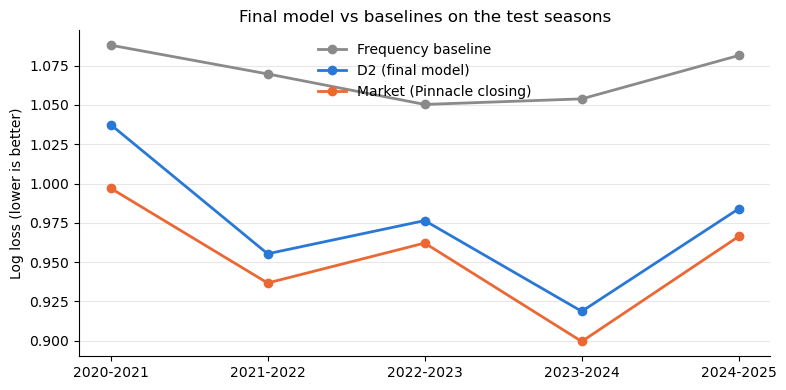

In [25]:
# Log loss per test season: frequency baseline, final model, market
os.makedirs("figures", exist_ok=True)     # figures used in the README
fig, ax = plt.subplots(figsize=(8, 4))
for name, label, color in [("Frequency", "Frequency baseline", "#8a8a8a"),
                           ("D2", "D2 (final model)", "#2a78d6"),
                           ("Market", "Market (Pinnacle closing)", "#eb6834")]:
    ax.plot(TEST_SEASONS, scores[name], marker="o", linewidth=2, color=color, label=label)
ax.set_ylabel("Log loss (lower is better)")
ax.set_title("Final model vs baselines on the test seasons")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("figures/log_loss_by_season.png", dpi=150)
plt.show()

**Conclusion:** 8 comparisons were made on the test seasons and two changes were kept: C1, then D2. The final model D2
scores 0.974 on average and closes about 80% of the gap between the frequency baseline (1.069) and the closing market
(0.952); it never beats the market in any season. Both differences are clear: D2 beats the frequency baseline and
trails the market with 95% intervals far from zero.

The steps from A to C1 to D2 are small (about 0.005 in total) and each interval includes zero, so A, C1, C2, C3, D1 and D2
perform almost the same: Elo carries most of the signal. D1 has an almost identical mean (0.9742 against 0.9744) but
failed the rule because it was less consistent across seasons.


## 6. Calibration

Do D2's probabilities mean what they say? Among matches where D2 gives a home win about 60%, about 60% should be home
wins. For each outcome, the 1,900 test matches are split into 5 groups of equal size by predicted probability, and the
mean prediction is compared with the actual share. With 380 matches per group, a gap of about 0.02 can be chance;
`z` measures the gap in standard errors, and only |z| above about 2 deserves attention.



In [26]:
def calibration_table(probs, n_groups=5):
    results = matches.loc[probs.index, "FTR"]
    parts = []
    for outcome in ["H", "D", "A"]:
        table = pd.DataFrame({
            "predicted": probs[outcome],                        # predicted probability of this outcome
            "happened": (results == outcome).astype(int),      # 1 if this outcome happened, else 0
            "group": pd.qcut(probs[outcome], n_groups, labels=False),   # 5 groups of equal size
        })
        grouped = table.groupby("group")[["predicted", "happened"]].mean()
        grouped.columns = ["mean_pred", "actual"]
        grouped["n"] = table.groupby("group").size()
        grouped["outcome"] = outcome
        parts.append(grouped)
    cal = pd.concat(parts)
    cal["gap"] = cal["actual"] - cal["mean_pred"]
    standard_error = np.sqrt(cal["mean_pred"] * (1 - cal["mean_pred"]) / cal["n"])
    cal["z"] = cal["gap"] / standard_error                      # gap measured in standard errors
    return cal


cal_d2 = calibration_table(probs["D2"])
display(cal_d2.round(3))
print("Groups with |z| > 2:", int((cal_d2["z"].abs() > 2).sum()), "of", len(cal_d2))

,mean_pred,actual,n,outcome,gap,z
group,,,,,,
0,0.175,0.161,380,H,-0.015,-0.763
1,0.330,0.305,380,H,-0.025,-1.021
2,0.448,0.447,380,H,-0.001,-0.035
3,0.573,0.550,380,H,-0.023,-0.901
4,0.733,0.697,380,H,-0.035,-1.561
0,0.167,0.174,380,D,0.007,0.360
1,0.216,0.200,380,D,-0.016,-0.748
2,0.238,0.250,380,D,0.012,0.555
3,0.254,0.261,380,D,0.007,0.310


Groups with |z| > 2: 1 of 15


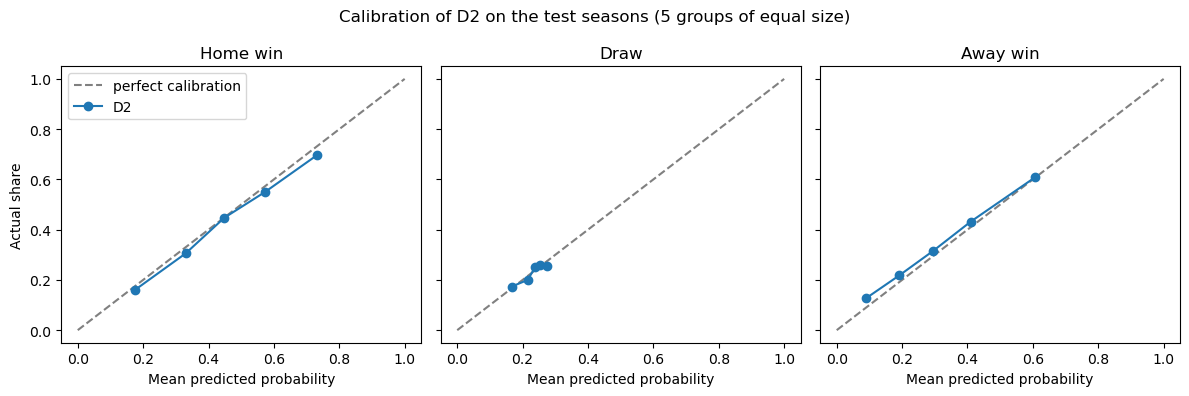

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True)
for ax, outcome, title in zip(axes, ["H", "D", "A"], ["Home win", "Draw", "Away win"]):
    part = cal_d2[cal_d2["outcome"] == outcome]
    ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="perfect calibration")
    ax.plot(part["mean_pred"], part["actual"], marker="o", label="D2")
    ax.set_title(title)
    ax.set_xlabel("Mean predicted probability")
axes[0].set_ylabel("Actual share")
axes[0].legend()
fig.suptitle("Calibration of D2 on the test seasons (5 groups of equal size)")
plt.tight_layout()
plt.savefig("figures/calibration.png", dpi=150)     # used in the README
plt.show()

In [28]:
# Average gap size per outcome, D2 vs market
cal_market = calibration_table(probs["Market"])
mean_abs_gap = pd.DataFrame({
    "D2": cal_d2["gap"].abs().groupby(cal_d2["outcome"]).mean(),
    "Market": cal_market["gap"].abs().groupby(cal_market["outcome"]).mean(),
})
display(mean_abs_gap.round(4))
print("Market groups with |z| > 2:", int((cal_market["z"].abs() > 2).sum()), "of", len(cal_market))

,D2,Market
outcome,,
A,0.0216,0.0199
D,0.0122,0.0213
H,0.0197,0.0138


Market groups with |z| > 2: 1 of 15


**Conclusion:** D2 is well calibrated: 14 of 15 groups are within 2 standard errors. The exception is the lowest away-win
group (8.9% predicted, 12.6% actual), about what chance gives among 15 groups. All home gaps are negative and all away
gaps positive: D2 slightly overstates home wins and understates away wins, consistent with home advantage being weaker
in the test seasons than in training. Draw probabilities stay between 0.17 and 0.28: the model cannot tell which matches
are draw-prone. The market is not clearly better calibrated: its gaps are smaller on home wins, D2's on draws, and both have one group
beyond 2 standard errors. So the market's lower log loss comes mainly from better information about each match, not
from calibration. Not corrected, to avoid another decision made on the test seasons.

## 7. Error analysis

These checks describe where the final model (D2) does well and badly. They do not change the model.

### 7.1 Home advantage over time

Calibration showed that D2 slightly overstates home wins and understates away wins. Has home advantage changed
over the seasons, and in which test seasons does D2 miss it most?

,home_win_share,away_win_share,mean_goal_diff
season,,,
2012-2013,0.437,0.279,0.318
2013-2014,0.471,0.324,0.379
2014-2015,0.453,0.303,0.382
2015-2016,0.413,0.305,0.284
2016-2017,0.492,0.287,0.395
2017-2018,0.455,0.284,0.384
2018-2019,0.476,0.337,0.316
2019-2020,0.453,0.305,0.311
2020-2021,0.379,0.403,0.011


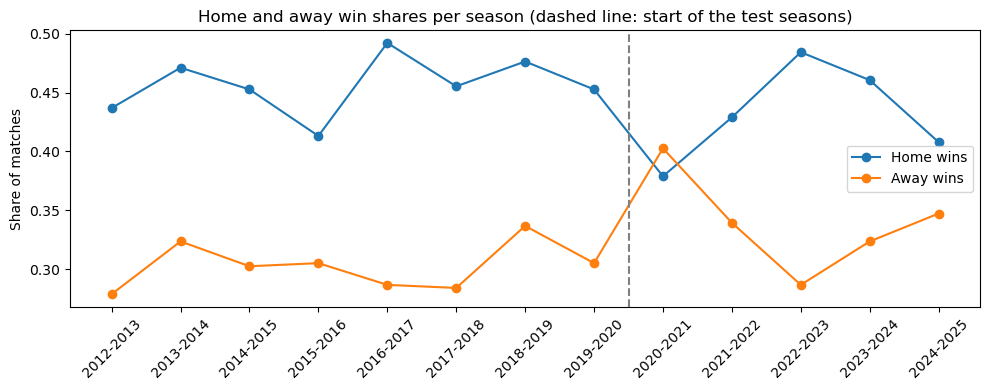

In [29]:
rows = []
for season in SEASONS:
    season_matches = matches[matches["Season"] == season]
    rows.append({
        "season": season,
        "home_win_share": (season_matches["FTR"] == "H").mean(),
        "away_win_share": (season_matches["FTR"] == "A").mean(),
        "mean_goal_diff": (season_matches["FTHG"] - season_matches["FTAG"]).mean(),   # home goals minus away goals
    })
home_adv = pd.DataFrame(rows).set_index("season")
display(home_adv.round(3))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(home_adv.index, home_adv["home_win_share"], marker="o", label="Home wins")
ax.plot(home_adv.index, home_adv["away_win_share"], marker="o", label="Away wins")
ax.axvline(7.5, linestyle="--", color="grey")          # line between training and test seasons
ax.set_ylabel("Share of matches")
ax.set_title("Home and away win shares per season (dashed line: start of the test seasons)")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [30]:
rows = []
for season in TEST_SEASONS:
    season_probs = probs["D2"][matches.loc[probs["D2"].index, "Season"] == season]
    season_results = matches.loc[season_probs.index, "FTR"]
    rows.append({
        "season": season,
        "predicted_home": season_probs["H"].mean(),        # average predicted probability of a home win
        "actual_home": (season_results == "H").mean(),     # share of home wins that actually happened
        "predicted_away": season_probs["A"].mean(),
        "actual_away": (season_results == "A").mean(),
    })
by_season = pd.DataFrame(rows).set_index("season")
by_season["home_gap"] = by_season["actual_home"] - by_season["predicted_home"]
by_season["away_gap"] = by_season["actual_away"] - by_season["predicted_away"]
display(by_season.round(3))

,predicted_home,actual_home,predicted_away,actual_away,home_gap,away_gap
season,,,,,,
2020-2021,0.460,0.379,0.308,0.403,-0.081,0.094
2021-2022,0.450,0.429,0.321,0.339,-0.021,0.019
2022-2023,0.445,0.484,0.323,0.287,0.040,-0.036
2023-2024,0.451,0.461,0.321,0.324,0.009,0.003
2024-2025,0.453,0.408,0.319,0.347,-0.045,0.028


In [31]:
rows = []
for season in TEST_SEASONS:
    in_season = matches.loc[probs["D2"].index, "Season"] == season
    season_results = matches.loc[probs["D2"].index[in_season], "FTR"]
    rows.append({
        "season": season,
        "market_home": probs["Market"][in_season]["H"].mean(),
        "d2_home": probs["D2"][in_season]["H"].mean(),
        "actual_home": (season_results == "H").mean(),
    })
display(pd.DataFrame(rows).set_index("season").round(3))

,market_home,d2_home,actual_home
season,,,
2020-2021,0.413,0.460,0.379
2021-2022,0.434,0.450,0.429
2022-2023,0.437,0.445,0.484
2023-2024,0.452,0.451,0.461
2024-2025,0.449,0.453,0.408


**Conclusion:** home advantage varies between seasons, but 2020/21 stands out: matches were played without
crowds, home wins fell to 37.9% (below away wins, 40.3%) and the mean goal difference was close to zero. D2
predicts about the same home advantage every season (around 0.45), so it overstated home wins by 0.081 that
season. This one season explains most of the home bias seen in the calibration: without 2020/21, the average
gap is close to zero. Other seasonal gaps (±0.02 to ±0.045) are within chance for 380 matches. The market had
already lowered its home expectation in 2020/21 (41.3%), using information outside our data (empty stadiums).

### 7.2 Draws

D2's draw probabilities only range from 0.17 to 0.28. Draws are the least predictable outcome. We check when
draws are likely, how often the draw is the most likely outcome, and how much of the log loss comes from draws.

In [32]:
analysis = matches[~matches["Season"].isin(WARMUP_SEASONS)].copy()
analysis["closeness"] = (analysis["elo_diff"] + HOME_ADV).abs()
analysis["closeness_group"] = pd.qcut(analysis["closeness"], 4, labels=["closest", "2", "3", "furthest"])
analysis["draw"] = (analysis["FTR"] == "D").astype(int)
display(analysis.groupby("closeness_group", observed=True)["draw"].mean().round(3))

closeness_group
closest     0.257
2           0.271
3           0.232
furthest    0.168
Name: draw, dtype: float64

In [33]:
print("Draw is the most likely outcome | D2:", (probs["D2"].idxmax(axis=1) == "D").sum(),
      "| market:", (probs["Market"].idxmax(axis=1) == "D").sum(), "of", len(probs["D2"]), "matches")
print("Highest draw probability | D2:", round(probs["D2"]["D"].max(), 3),
      "| market:", round(probs["Market"]["D"].max(), 3))

Draw is the most likely outcome | D2: 0 | market: 0 of 1900 matches
Highest draw probability | D2: 0.325 | market: 0.337


In [34]:
results = matches.loc[probs["D2"].index, "FTR"]

cost_by_outcome = {}
for name in ["D2", "Market"]:
    cost = match_costs(probs[name], results)
    cost_by_outcome[name] = cost.groupby(results).mean()
    print(name, "| share of total loss from draws:", round(cost[results == "D"].sum() / cost.sum(), 3))

cost_table = pd.DataFrame(cost_by_outcome)
cost_table["share_of_matches"] = results.value_counts(normalize=True)
display(cost_table.round(3))

D2 | share of total loss from draws: 0.341
Market | share of total loss from draws: 0.338


,D2,Market,share_of_matches
FTR,,,
A,1.017,0.962,0.340
D,1.457,1.413,0.228
H,0.687,0.702,0.432


**Conclusion:** draws are more likely when the teams are evenly matched (25.7% and 27.1% in the two closest quarters
of matches, 16.8% in the furthest), but even then they are never the most likely outcome: neither D2 nor the
market gives a draw the highest probability in any of the 1,900 test matches. Draws are therefore the most
expensive outcome: 22.8% of matches but 34% of D2's total log loss (33.8% for the market). Most of the
market's advantage over D2 comes from away wins, then draws; D2's lower cost on home wins reflects its lean
towards the home side, not better home predictions.

### 7.3 Promoted teams

D2 added `promoted_fade_diff` because promoted clubs start at a carried-over Elo that doesn't reflect their new league. This section checks where that helps:
matches with vs without a promoted club, and the first 10 rounds (first 100 matches of a season) vs the rest.

In [35]:
test_index = probs["D2"].index
info = matches.loc[test_index, ["Season", "promoted_home", "promoted_away"]].copy()
info["has_promoted"] = (info["promoted_home"] == 1) | (info["promoted_away"] == 1)

# position of each match inside its season (matches is sorted by date)
match_number = matches.groupby("Season").cumcount()
info["stage"] = "rest of season"
info.loc[match_number.loc[test_index] < 100, "stage"] = "first 10 rounds"

for name in ["A", "C1", "D2", "Market"]:
    info[name] = match_costs(probs[name], matches.loc[test_index, "FTR"])

summary_promoted = info.groupby(["has_promoted", "stage"])[["A", "C1", "D2", "Market"]].mean()
summary_promoted["n"] = info.groupby(["has_promoted", "stage"]).size()
summary_promoted["D2_gap_to_market"] = summary_promoted["D2"] - summary_promoted["Market"]
display(summary_promoted.round(4))

A      C1      D2  Market     n  \
has_promoted stage                                                   
False        first 10 rounds  1.0060  0.9992  0.9989  0.9776   357   
             rest of season   1.0111  1.0038  1.0033  0.9803  1003   
True         first 10 rounds  0.8846  0.8802  0.8701  0.8757   143   
             rest of season   0.9099  0.9157  0.9170  0.8867   397   

                              D2_gap_to_market  
has_promoted stage                              
False        first 10 rounds            0.0213  
             rest of season             0.0230  
True         first 10 rounds           -0.0056  
             rest of season             0.0303

**Conclusion 7.3:** Matches involving a promoted club are easier to predict (lower log loss for all models).
`promoted_fade_diff` helps where it was designed to: in the first 10 rounds D2 improves on C1 by 0.010 (143 matches, small sample).
After round 10 it adds nothing, and D2's gap to the market is largest on promoted-club matches (0.030), so the model's weakness on promoted teams later in the season remains.

## 8. Final holdout: 2025/26

D2 is frozen: same features, same pipeline, no changes after seeing these results.
It is fit once on 2013/14–2024/25 and scored once on 2025/26, a season not used for any choice so far.

Pinnacle odds stop in January 2026 (210 of 380 matches). The market is therefore measured two ways:
Pinnacle closing odds on the 210 matches that have them, and the average closing odds over all bookmakers on all 380 matches.

In [36]:
HOLDOUT_SEASON = "2025-2026"
AVG_CLOSE_ODDS_COLS = ["AvgCH", "AvgCD", "AvgCA"]    # average closing odds over all bookmakers
FILE_COLS = ["Date", "HomeTeam", "AwayTeam"] + RESULT_COLS + STAT_COLS + PRE_CLOSE_ODDS_COLS + CLOSE_ODDS_COLS + AVG_CLOSE_ODDS_COLS

hold = pd.read_csv(HOLDOUT_SEASON + ".csv", usecols=FILE_COLS)
hold["Season"] = HOLDOUT_SEASON
hold["Date"] = pd.to_datetime(hold["Date"], dayfirst=True)
hold = hold.sort_values(["Date", "HomeTeam"]).reset_index(drop=True)

has_pinnacle = hold["PSCH"].notna()
complete_cols = ID_COLS + RESULT_COLS + STAT_COLS + AVG_CLOSE_ODDS_COLS     # all columns except Pinnacle

assert len(hold) == MATCHES_PER_SEASON
assert hold[complete_cols].isna().sum().sum() == 0
assert hold.duplicated(subset=KEY_COLS).sum() == 0
assert (hold["HomeTeam"].value_counts() == 19).all() and (hold["AwayTeam"].value_counts() == 19).all()
assert hold["Date"].min() > matches["Date"].max()            # starts after the last test match
print("Holdout checks passed")
print("Matches with Pinnacle closing odds:", has_pinnacle.sum(), "of", len(hold),
      "| last one on", hold.loc[has_pinnacle, "Date"].max().date())

Holdout checks passed
Matches with Pinnacle closing odds: 210 of 380 | last one on 2026-01-08


In [37]:
holdout_ratings = ratings.copy()
elo_home = []
elo_away = []

for i, match in hold.iterrows():
    home = match["HomeTeam"]
    away = match["AwayTeam"]
    elo_home.append(holdout_ratings[home])
    elo_away.append(holdout_ratings[away])

    expected = expected_home_score(holdout_ratings[home], holdout_ratings[away])
    change = K_FACTOR * (SCORE_FOR_HOME[match["FTR"]] - expected)
    holdout_ratings[home] = holdout_ratings[home] + change
    holdout_ratings[away] = holdout_ratings[away] - change

hold["elo_diff"] = np.array(elo_home) - np.array(elo_away)

In [38]:
hold["match_id"] = len(matches) + hold.index         # new ids after the last id of matches

hold_home = hold[view_cols].rename(columns=HOME_VIEW)
hold_home["venue"] = "H"
hold_away = hold[view_cols].rename(columns=AWAY_VIEW)
hold_away["venue"] = "A"

base_cols = ["match_id", "Season", "Date", "team", "venue", "goals_for", "goals_against", "sot_for", "sot_against"]
all_teams = pd.concat([team_table[base_cols], hold_home, hold_away])
all_teams = all_teams.sort_values(["Date", "match_id"]).reset_index(drop=True)
all_teams["gd"] = all_teams["goals_for"] - all_teams["goals_against"]
all_teams["sotd"] = all_teams["sot_for"] - all_teams["sot_against"]

# Last 5 matches
for team in all_teams["team"].unique():
    rows = all_teams["team"] == team
    for source, target in [("gd", "gd5"), ("sotd", "sotd5")]:
        previous = all_teams.loc[rows, source].shift(1)
        all_teams.loc[rows, target] = previous.rolling(FORM_WINDOW, min_periods=1).mean()


old_rows = all_teams[all_teams["Season"] != HOLDOUT_SEASON].set_index(["match_id", "venue"])
original = team_table.set_index(["match_id", "venue"]).loc[old_rows.index]
assert np.allclose(old_rows["gd5"], original["gd5"], equal_nan=True)
assert np.allclose(old_rows["sotd5"], original["sotd5"], equal_nan=True)

# Promoted: not in the league in 2024/25
hold_teams = all_teams[all_teams["Season"] == HOLDOUT_SEASON].copy()
previous_clubs = team_table.loc[team_table["Season"] == SEASONS[-1], "team"].unique()
hold_teams["promoted"] = (~hold_teams["team"].isin(previous_clubs)).astype(int)
games_played = hold_teams.groupby("team").cumcount()
hold_teams["promoted_fade"] = hold_teams["promoted"] * (1 - games_played / GAMES_PER_TEAM)
print("Promoted clubs:", list(hold_teams.loc[hold_teams["promoted"] == 1, "team"].unique()))


home_side = hold_teams[hold_teams["venue"] == "H"].set_index("match_id")
away_side = hold_teams[hold_teams["venue"] == "A"].set_index("match_id")
hold = hold.set_index("match_id")
for feature in ["gd5", "sotd5", "promoted_fade"]:
    hold[feature + "_diff"] = home_side[feature] - away_side[feature]

assert hold[FEATURES_D2].isna().sum().sum() == 0
print("Holdout features ready")

Promoted clubs: ['Sunderland', 'Burnley', 'Leeds']
Holdout features ready


In [39]:
final_train = matches[matches["Season"].isin(SEASONS[1:])]     # 2013/14 to 2024/25, warm-up excluded
assert final_train["Date"].max() < hold["Date"].min()

final_model = make_pipeline(SimpleImputer(strategy="mean"), StandardScaler(), LogisticRegression())
final_model.fit(final_train[FEATURES_D2], final_train["FTR"])
assert list(final_model.classes_) == OUTCOMES

frequency_model = DummyClassifier(strategy="prior")
frequency_model.fit(final_train[FEATURES_D2], final_train["FTR"])

hold_probs = {
    "Frequency": pd.DataFrame(frequency_model.predict_proba(hold[FEATURES_D2]), columns=OUTCOMES, index=hold.index),
    "D2": pd.DataFrame(final_model.predict_proba(hold[FEATURES_D2]), columns=OUTCOMES, index=hold.index),
    "Market, average": market_probs(hold, AVG_CLOSE_ODDS_COLS),
}

In [40]:
pinnacle_matches = hold[hold["PSCH"].notna()]
hold_probs_pinnacle = market_probs(pinnacle_matches, CLOSE_ODDS_COLS)

rows = []
for name in ["Frequency", "D2", "Market, average"]:
    rows.append({
        "model": name,
        "all_380_matches": log_loss(hold["FTR"], hold_probs[name], labels=OUTCOMES),
        "pinnacle_matches": log_loss(pinnacle_matches["FTR"], hold_probs[name].loc[pinnacle_matches.index], labels=OUTCOMES),
    })
rows.append({
    "model": "Market, Pinnacle",
    "all_380_matches": np.nan,                       # no Pinnacle odds after January
    "pinnacle_matches": log_loss(pinnacle_matches["FTR"], hold_probs_pinnacle, labels=OUTCOMES),
})
holdout_scores = pd.DataFrame(rows).set_index("model")
display(holdout_scores.round(4))

gap_all = (holdout_scores.loc["Frequency", "all_380_matches"] - holdout_scores.loc["D2", "all_380_matches"]) / \
          (holdout_scores.loc["Frequency", "all_380_matches"] - holdout_scores.loc["Market, average", "all_380_matches"])
gap_pinnacle = (holdout_scores.loc["Frequency", "pinnacle_matches"] - holdout_scores.loc["D2", "pinnacle_matches"]) / \
               (holdout_scores.loc["Frequency", "pinnacle_matches"] - holdout_scores.loc["Market, Pinnacle", "pinnacle_matches"])
print("D2 gap closed | vs average market, all matches:", round(gap_all, 3),
      "| vs Pinnacle, matches with Pinnacle odds:", round(gap_pinnacle, 3))

,all_380_matches,pinnacle_matches
model,,
Frequency,1.0841,1.0715
D2,1.0412,1.0147
"Market, average",1.0118,0.9836
"Market, Pinnacle",NaN,0.9875


D2 gap closed | vs average market, all matches: 0.593 | vs Pinnacle, matches with Pinnacle odds: 0.675


### Uncertainty of the holdout result

One season is 380 matches, so the holdout scores are noisy. Same bootstrap as in section 5, resampling the holdout matches.

In [41]:
cost_freq = match_costs(hold_probs["Frequency"], hold["FTR"])
cost_d2 = match_costs(hold_probs["D2"], hold["FTR"])
cost_avg = match_costs(hold_probs["Market, average"], hold["FTR"])
cost_pin = match_costs(hold_probs_pinnacle, pinnacle_matches["FTR"])
pin_index = pinnacle_matches.index


def bootstrap_gap_closed(cost_freq, cost_model, cost_market):
    """95% interval of the share of the frequency-to-market gap closed by the model."""
    rng = np.random.default_rng(RANDOM_SEED)
    n = len(cost_model)
    samples = []
    for b in range(N_BOOT):
        pick = rng.integers(0, n, n)
        f = cost_freq.values[pick].mean()
        d = cost_model.values[pick].mean()
        m = cost_market.values[pick].mean()
        samples.append((f - d) / (f - m))
    return np.percentile(samples, 2.5), np.percentile(samples, 97.5)


rows = []
for label, diff in [("D2 gain over frequency, all matches", cost_freq - cost_d2),
                    ("D2 behind average market, all matches", cost_d2 - cost_avg),
                    ("D2 behind Pinnacle, Pinnacle matches", cost_d2.loc[pin_index] - cost_pin)]:
    low, high = bootstrap_ci(diff)
    rows.append({"comparison": label, "mean": diff.mean(), "ci_low": low, "ci_high": high})

low, high = bootstrap_gap_closed(cost_freq, cost_d2, cost_avg)
rows.append({"comparison": "Gap closed vs average market, all matches", "mean": gap_all, "ci_low": low, "ci_high": high})
low, high = bootstrap_gap_closed(cost_freq.loc[pin_index], cost_d2.loc[pin_index], cost_pin)
rows.append({"comparison": "Gap closed vs Pinnacle, Pinnacle matches", "mean": gap_pinnacle, "ci_low": low, "ci_high": high})

display(pd.DataFrame(rows).set_index("comparison").round(4))

,mean,ci_low,ci_high
comparison,,,
"D2 gain over frequency, all matches",0.0429,0.0005,0.0827
"D2 behind average market, all matches",0.0294,0.0089,0.0500
"D2 behind Pinnacle, Pinnacle matches",0.0273,-0.0013,0.0567
"Gap closed vs average market, all matches",0.5931,0.0134,0.8765
"Gap closed vs Pinnacle, Pinnacle matches",0.6754,-0.0003,1.0156


### Two checks on the market comparison

1. The holdout uses average closing odds where Pinnacle is missing. Are they a fair stand-in? Score them on the test seasons.
2. The 210 matches with Pinnacle odds are the first part of the season (August to early January). Is the model's
   gap to the market different in the rest of the season?

In [42]:
# Check 1: average closing odds on the test seasons
avg_parts = []
for season in TEST_SEASONS:
    avg_parts.append(seasons_data[season][["Season", "HomeTeam", "AwayTeam"] + AVG_CLOSE_ODDS_COLS])
test_avg = test_matches.merge(pd.concat(avg_parts), on=["Season", "HomeTeam", "AwayTeam"])
assert len(test_avg) == len(test_matches) and test_avg[AVG_CLOSE_ODDS_COLS].isna().sum().sum() == 0
print("Test seasons | Pinnacle closing:", round(log_loss(test_matches["FTR"], closing_probs, labels=OUTCOMES), 4),
      "| average closing:", round(log_loss(test_avg["FTR"], market_probs(test_avg, AVG_CLOSE_ODDS_COLS), labels=OUTCOMES), 4))

# Check 2: holdout against average odds, matches with and without Pinnacle odds
rows = []
for label, index in [("with Pinnacle odds (Aug to early Jan)", pin_index),
                     ("without Pinnacle odds (Jan to May)", hold.index[hold["PSCH"].isna()])]:
    f = cost_freq.loc[index].mean()
    d = cost_d2.loc[index].mean()
    m = cost_avg.loc[index].mean()
    rows.append({"matches": label, "n": len(index), "frequency": f, "D2": d, "average_market": m,
                 "gap_closed": (f - d) / (f - m)})
display(pd.DataFrame(rows).set_index("matches").round(4))

Test seasons | Pinnacle closing: 0.9524 | average closing: 0.9525


,n,frequency,D2,average_market,gap_closed
matches,,,,,
with Pinnacle odds (Aug to early Jan),210,1.0715,1.0147,0.9836,0.6460
without Pinnacle odds (Jan to May),170,1.0995,1.0738,1.0465,0.4849


In [43]:
shares_hold = pd.DataFrame({
    "test_seasons": test_matches["FTR"].value_counts(normalize=True),
    "holdout": hold["FTR"].value_counts(normalize=True),
    "D2_predicted": hold_probs["D2"].mean(),
})
display(shares_hold.round(3))

,test_seasons,holdout,D2_predicted
A,0.340,0.300,0.318
D,0.228,0.274,0.234
H,0.432,0.426,0.448


**Conclusion 8:** On 2025/26, never used before, D2 beats the frequency baseline (1.0412 vs 1.0841) and stays behind the
market (1.0118 average odds; 0.9875 Pinnacle on the 210 matches with its odds).

The holdout is one season of 380 matches, so these numbers are noisy:
- D2's gain over the frequency baseline is 0.043, with a 95% interval of 0.0005 to 0.083: positive, but only just.
- D2 is 0.029 behind the average market on all matches (interval 0.009 to 0.050): clearly behind. Against Pinnacle on
  the 210 matches with its odds, the gap is 0.027 but its interval (−0.001 to 0.057) includes zero.
- Gap closed: 59% against average odds on all matches (interval 1% to 88%); 68% against Pinnacle on the 210 matches
  (interval 0% to 102%).

The two checks explain the difference between 59% and 68%. Average closing odds are as good a benchmark as Pinnacle
(0.9525 vs 0.9524 on the test seasons), so the choice of market barely matters. What matters is which matches: on the
same 210 matches, the gap closed against average odds is 65%, but on the 170 matches from January onwards it is 49%.

Possible reasons for the lower holdout estimate, not proven: draws rose to 27.4% (22.8% in the test seasons) while D2
still predicts about 23% (section 7.2 showed draws are the outcome no model handles well), and the test seasons were
reused for 8 comparisons, which makes their score slightly optimistic.


## 9. Conclusions

**Answer to the question:** a logistic regression on four pre-match features (Elo difference, goal and shots-on-target
differences over the last 5 matches, a fading promoted-club flag) beats the base-rate forecast but not the betting market.

| | Test seasons 2020/21–2024/25 | Holdout 2025/26 |
|---|---|---|
| Frequency baseline | 1.069 | 1.084 |
| D2 | 0.974 | 1.041 |
| Market (closing) | 0.952 (Pinnacle; average odds 0.9525) | 1.012 (average odds) |
| Gap closed by D2 | about 80% | 59% (95% interval 1% to 88%) |

**What worked:** Elo carries most of the signal. Recent goal and shot differences and a promoted-club flag add a little,
but those gains are within noise (95% intervals include zero).
**What did not:** recent form (already inside Elo), season-to-date statistics, gradient boosting.

**Limitations**
- Only Premier League matches: no European or cup fixtures, so rest days and fixture congestion are not modelled.
- No team news (injuries, line-ups), which the market has.
- Draws are never the most likely outcome for the model, and they account for about a third of its log loss.
- A club returning after years outside the league keeps its old Elo rating and its old last-5 statistics
  (for example Sunderland in 2025/26, last seen in 2016/17); only the fading promoted flag corrects for it.
- The 95% intervals were added after the model was chosen; with them, a stricter rule would probably have kept a
  simpler model (A or C1), with almost the same score.
- The test seasons were used for 8 comparisons; the holdout is the unbiased estimate, but it is a single season,
  and Pinnacle odds cover only 210 of its matches.

**Future work:** add European and cup fixtures to model rest days; tune the Elo settings (K, home advantage) on training
seasons only; shrink ratings toward the average between seasons; model draws directly (for example from expected goals).